Develop a mini project in a group using different predictive models techniques to solve any real life problem.

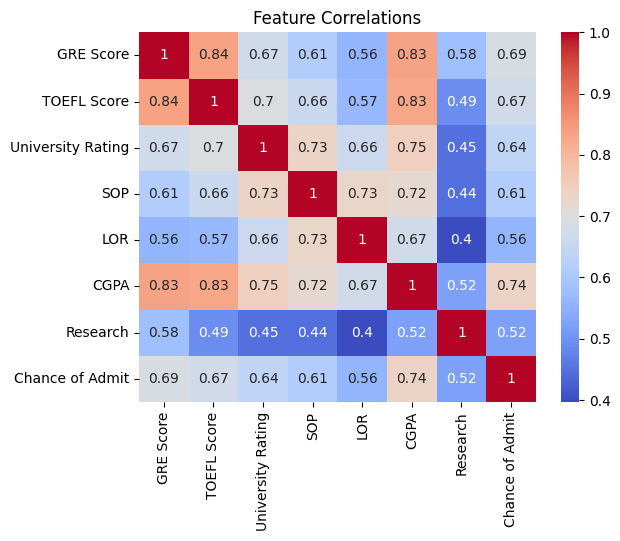

Linear Regression Accuracy: 68.09 %
Random Forest Accuracy: 71.49 %
Predicted Admission Chance: 74.67 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# 1. Load & Clean Data (using Pandas)
df = pd.read_csv('Admission_Predict.csv')
df.columns = df.columns.str.strip() # Fix spaces in column names
df = df.drop('Serial No.', axis=1)  # Remove ID column as it doesn't affect admission

# 2. Visualize (using Seaborn & Matplotlib)
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlations")
plt.show()

# 3. Split Data into Train/Test
X = df.drop('Chance of Admit', axis=1)
y = df['Chance of Admit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train Predictive Models
# Model A: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Model B: Random Forest
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# 5. Evaluate Accuracy (R-squared score converted to percentage)
print("Linear Regression Accuracy:", round(r2_score(y_test, lr_pred) * 100, 2), "%")
print("Random Forest Accuracy:", round(r2_score(y_test, rf_pred) * 100, 2), "%")

# 6. Predict a New Student's Chances
# Features: [GRE, TOEFL, Univ Rating, SOP, LOR, CGPA, Research]
new_student = [[320, 110, 4, 4.0, 4.0, 9.0, 1]]
prediction = lr.predict(new_student)
print("Predicted Admission Chance:", round(prediction[0] * 100, 2), "%")